# How the geometric and energy priors work

This notebook demonstrates the two priors of `DoseTrainer.generate_prior` on a synthetic batch.

- **Geometric prior** (the ADoTA beam shape): a Gaussian tube around the ray axis, constant along the beam.
- **Energy prior**: a Bragg-curve-like field with an entrance plateau, a peak at the ray target and a fall-off behind it.

Both priors depend only on where a voxel sits relative to the beam: $\delta$ is the distance from the ray target along the beam axis, $r$ is the distance from the axis. Neither of them uses the CT values.

The batch has the same structure as in training, so the same cells also run on a real batch (`batch = next(iter(val_loader))`).

In [2]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from scripts.training_boys import DoseTrainer

plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "font.size": 9,
    "axes.linewidth": 0.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "lines.linewidth": 1.0,
    "legend.frameon": False,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.0,
})
CM = 1 / 2.54          # cm -> inch
SAVE_FIGS = False      # True: every figure is also saved as PDF


def finish(fig, name):
    if SAVE_FIGS:
        fig.savefig(f"{name}.pdf")
    plt.show()

## 1. Synthetic batch

The patch has 128×128×32 voxels of 1×1×3 mm. It is cut from a 443×440×133 CT the same way as in the pipeline: centred in x–y, starting at `z_start` in z. `affine_trans` is the RAS affine of the original image (as loaded by MONAI), and the ray end points are in LPS, in mm (as in the ray JSON).

The batch holds four beams with different groups, energies and directions. The ray source lies 300 mm upstream of the target; the priors only use its direction. The CT is a simple phantom (body, plus lungs for TH) that only serves for orientation.

In [3]:
SPACING = np.array([1.0, 1.0, 3.0])               # voxel size [mm]
ORIG_SHAPE = np.array([443, 440, 133])            # original CT
PATCH = (128, 128, 32)                            # network input
Z_START = 50                                      # first slice of the patch in the original CT
ORIGIN_LPS = np.array([-221.0, -219.5, -650.0])   # world position of original voxel (0, 0, 0), LPS [mm]
CROP = np.array([(ORIG_SHAPE[0] - PATCH[0]) // 2, (ORIG_SHAPE[1] - PATCH[1]) // 2, Z_START])

# RAS affine of the original image, as MONAI loads it: x_RAS = AFFINE @ (i, j, k, 1)
AFFINE = np.diag([-SPACING[0], -SPACING[1], SPACING[2], 1.0])
AFFINE[:3, 3] = ORIGIN_LPS * [-1, -1, 1]


def patch_to_lps(ijk):
    """Patch voxel index -> world LPS [mm]."""
    return ORIGIN_LPS + SPACING * (np.asarray(ijk, float) + CROP)


def lps_to_patch(x):
    """World LPS [mm] -> patch voxel index."""
    return (np.asarray(x, float) - ORIGIN_LPS) / SPACING - CROP

In [4]:
#        group  E [MeV]  direction in the x-y plane [deg]  target offset from the patch centre [mm]
BEAMS = [("TH", 150.0,  30.0, (  0.0,  10.0, 0.0)),
         ("TH",  90.0, 140.0, ( 15.0, -10.0, 0.0)),
         ("AB",  70.0, 250.0, (-10.0, -30.0, 0.0)),
         ("AB", 180.0, 330.0, ( 15.0,   5.0, 0.0))]


def phantom(groups):
    """CT for orientation only (HU / 1000): body ellipse, lungs for TH."""
    X, Y, Z = PATCH
    i, j = np.meshgrid(np.arange(X), np.arange(Y), indexing="ij")
    body = ((i - 64) / 58) ** 2 + ((j - 64) / 46) ** 2 < 1
    lungs = (((i - 38) / 17) ** 2 + ((j - 68) / 25) ** 2 < 1) | (((i - 90) / 17) ** 2 + ((j - 68) / 25) ** 2 < 1)
    ct = np.empty((len(groups), 1, X, Y, Z))
    for b, group in enumerate(groups):
        axial = np.where(body, 0.0, -1.0)
        if group == "TH":
            axial = np.where(lungs, -0.75, axial)
        ct[b, 0] = axial[..., None]
    return ct


def make_batch(beams):
    centre = np.array(PATCH) / 2
    targets, sources = [], []
    for group, energy, angle, offset in beams:
        u = np.array([np.cos(np.radians(angle)), np.sin(np.radians(angle)), 0.0])
        target = patch_to_lps(centre + np.asarray(offset) / SPACING)
        targets.append(target)
        sources.append(target - 300.0 * u)
    B = len(beams)
    f32 = dict(dtype=torch.float32)
    condition = torch.zeros(B, 3, **f32)
    condition[:, 2] = torch.tensor([beam[1] for beam in beams], **f32)
    return {
        "ct": torch.tensor(phantom([beam[0] for beam in beams]), **f32),
        "gt_dose": torch.zeros(B, 1, *PATCH, **f32),
        "condition": condition,
        "phys_source": torch.tensor(np.array(sources), **f32),
        "phys_target": torch.tensor(np.array(targets), **f32),
        "affine_trans": torch.tensor(AFFINE, **f32).repeat(B, 1, 1),
        "z_start": torch.full((B,), Z_START),
        "orig_shape": torch.tensor(ORIG_SHAPE).repeat(B, 1),
        "group": [beam[0] for beam in beams],
    }


batch = make_batch(BEAMS)
{k: (tuple(v.shape) if torch.is_tensor(v) else v) for k, v in batch.items()}

{'ct': (4, 1, 128, 128, 32),
 'gt_dose': (4, 1, 128, 128, 32),
 'condition': (4, 3),
 'phys_source': (4, 3),
 'phys_target': (4, 3),
 'affine_trans': (4, 4, 4),
 'z_start': (4,),
 'orig_shape': (4, 3),
 'group': ['TH', 'TH', 'AB', 'AB']}

## 2. Generating the priors

`generate_prior` takes keyword arguments only:

- `batch`: required;
- `kind`: `"geometric"` (default) or `"energy"`;
- any parameter can be overridden: `sigma`, `range_fits`, `sigma_lat0`, `sigma_lat_slope`, `plateau`, `sigma_entrance`, `sigma_distal`.

Both calls return a `(B, 1, X, Y, Z)` field, and `predict` concatenates them to the CT.

In [5]:
trainer = DoseTrainer(model=torch.nn.Identity())   # the model plays no role in prior generation

geo = trainer.generate_prior(batch=batch)                     # geometric prior
energy = trainer.generate_prior(batch=batch, kind="energy")   # energy prior
x = torch.cat([batch["ct"], geo, energy], dim=1)              # network input, as in predict

print("geometric:", tuple(geo.shape), "  energy:", tuple(energy.shape), "  input:", tuple(x.shape))

geometric: (4, 1, 128, 128, 32)   energy: (4, 1, 128, 128, 32)   input: (4, 3, 128, 128, 32)


## 3. Geometry: where the beam runs

The figures show an axial slice of the patch at the height of the target, in the patch's own coordinates (mm).

- Dashed line: the beam axis, i.e. the ray source → ray target line.
- ×: the ray target; the energy prior puts the Bragg peak here.
- ○: the fitted source $s' = t - L(E)\,u$, where the energy prior starts. $L(E)$ is the group-wise length–energy fit.

$s'$ is only visible when it falls inside the patch, here for the AB 70 MeV beam.

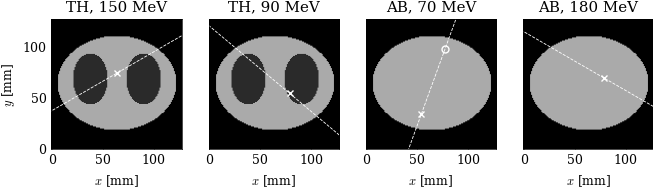

In [6]:
FITS = {"TH": (36.99015255, 0.5, -208.1400), "AB": (0.09815625, 1.485708, 13.5085)}   # defaults of generate_prior


def fitted_length(group, energy):
    a, b, c = FITS[group]
    return max(a * energy**b + c, 1.0)


def beam_geometry(batch, b):
    """Target t (LPS), unit direction u, fitted length L and energy E of beam b."""
    s = batch["phys_source"][b].double().numpy()
    t = batch["phys_target"][b].double().numpy()
    u = (t - s) / np.linalg.norm(t - s)
    E = float(batch["condition"][b, 2])
    return t, u, fitted_length(batch["group"][b], E), E


def show_slice(ax, volume, b, cmap, vmin=None, vmax=None):
    """Axial slice of volume (B, 1, X, Y, Z) through the target of beam b, with the beam drawn on it."""
    t, u, L, E = beam_geometry(batch, b)
    t_vox = lps_to_patch(t)
    X, Y, _ = PATCH
    im = ax.imshow(volume[b, 0, :, :, int(round(t_vox[2]))].T, origin="lower", cmap=cmap,
                   vmin=vmin, vmax=vmax, extent=[-0.5, X - 0.5, -0.5, Y - 0.5])   # 1 mm voxels: index = mm
    t_mm = t_vox[:2] * SPACING[:2]
    ax.plot(*np.c_[t_mm - 400 * u[:2], t_mm + 400 * u[:2]], ls="--", lw=0.6, color="w")
    ax.plot(*t_mm, "x", color="w", ms=5, mew=1)
    s_fit = lps_to_patch(t - L * u)[:2] * SPACING[:2]
    if (s_fit >= 0).all() and (s_fit < [X, Y]).all():
        ax.plot(*s_fit, "o", mfc="none", mec="w", ms=5, mew=1)
    ax.set_xlim(-0.5, X - 0.5)
    ax.set_ylim(-0.5, Y - 0.5)
    ax.set_title(f"{batch['group'][b]}, {E:.0f} MeV")
    ax.set_xlabel("$x$ [mm]")
    return im


fig, axes = plt.subplots(1, 4, figsize=(17.2 * CM, 4.8 * CM), sharey=True, layout="constrained")
for b, ax in enumerate(axes):
    show_slice(ax, batch["ct"], b, cmap="gray", vmin=-1.0, vmax=0.5)
axes[0].set_ylabel("$y$ [mm]")
finish(fig, "fig1_geometry")

## 4. Geometric prior

$$\Phi(\mathbf p) = \exp\!\left(-\frac{r^2}{2\sigma^2}\right), \qquad \sigma = 2\ \text{mm}$$

The field is constant along the axis, so it runs through the whole patch. It encodes which line the beam travels on, not where it stops: it depends neither on the energy nor on where the target sits along the line.

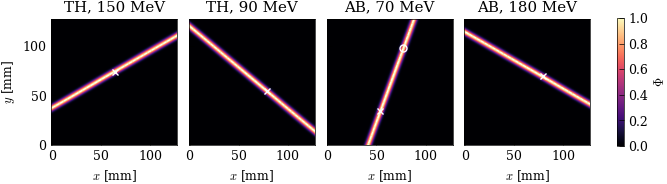

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(17.2 * CM, 4.8 * CM), sharey=True, layout="constrained")
for b, ax in enumerate(axes):
    im = show_slice(ax, geo, b, cmap="magma", vmin=0, vmax=1)
axes[0].set_ylabel("$y$ [mm]")
fig.colorbar(im, ax=axes, shrink=0.8, label=r"$\Phi$")
finish(fig, "fig2_geometric_slices")

### Profiles along and across the beam

`generate_prior` can be evaluated on any voxel grid described by `affine_trans`. For the profiles we therefore lay a 1D grid along the beam axis, and another one across it at the target. The curves are exact outputs of the method, not values interpolated from the 3D field.

The left panel shows both priors on the same axis: the geometric prior is 1 everywhere, while the energy prior starts at $s'$ and falls off behind the target. The right panel also shows a `sigma` override; the dots are the analytic values $\exp(-r^2/2\sigma^2)$.

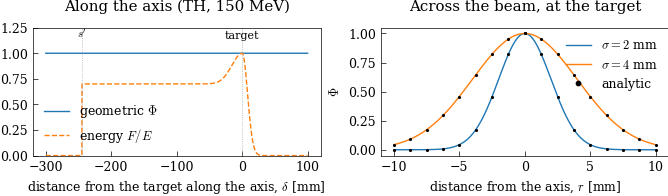

In [8]:
def probe(batch, b, start_lps, step_lps, n, energy=None, group=None, **prior_kwargs):
    """generate_prior of beam b on the n points start + m * step (LPS mm), m = 0 .. n-1."""
    affine = np.zeros((4, 4))
    affine[:3, 0] = np.asarray(step_lps) * [-1, -1, 1]     # LPS -> RAS
    affine[:3, 3] = np.asarray(start_lps) * [-1, -1, 1]
    affine[3, 3] = 1.0
    condition = batch["condition"][b:b + 1].double().clone()
    if energy is not None:
        condition[0, 2] = energy
    line = {
        "ct": torch.zeros(1, 1, n, 1, 1, dtype=torch.float64),
        "phys_source": batch["phys_source"][b:b + 1].double(),
        "phys_target": batch["phys_target"][b:b + 1].double(),
        "condition": condition,
        "group": [group or batch["group"][b]],
        "affine_trans": torch.tensor(affine)[None],
        "orig_shape": torch.tensor([[n, 1, 1]]),           # no crop offset
        "z_start": torch.zeros(1),
    }
    return trainer.generate_prior(batch=line, **prior_kwargs)[0, 0, :, 0, 0].numpy()


b = 0
t, u, L, E = beam_geometry(batch, b)
e_perp = np.array([-u[1], u[0], 0.0])                     # in-plane direction perpendicular to the beam

delta = np.arange(-300.0, 100.0, 0.25)                     # distance from the target along the beam [mm]
along_geo = probe(batch, b, t + delta[0] * u, 0.25 * u, len(delta))
along_energy = probe(batch, b, t + delta[0] * u, 0.25 * u, len(delta), kind="energy") / E

r = np.arange(-10.0, 10.0 + 1e-9, 0.05)                    # signed distance from the axis at the target [mm]
across = {s: probe(batch, b, t + r[0] * e_perp, 0.05 * e_perp, len(r), sigma=s) for s in (2.0, 4.0)}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17.2 * CM, 5.2 * CM), layout="constrained")
ax1.plot(delta, along_geo, label=r"geometric $\Phi$")
ax1.plot(delta, along_energy, "--", label=r"energy $F/E$")
for pos, text in ((0.0, "target"), (-L, "$s'$")):
    ax1.axvline(pos, color="0.6", lw=0.5, ls=":")
    ax1.text(pos, 1.12, text, ha="center", va="bottom", fontsize=8)
ax1.set_ylim(0, 1.25)
ax1.set_xlabel(r"distance from the target along the axis, $\delta$ [mm]")
ax1.set_title(f"Along the axis ({batch['group'][b]}, {E:.0f} MeV)", pad=12)
ax1.legend(loc="lower left")

for s, prof in across.items():
    ax2.plot(r, prof, label=rf"$\sigma = {s:.0f}$ mm")
    ax2.plot(r[::25], np.exp(-r[::25] ** 2 / (2 * s**2)), "k.", ms=2.5, label="analytic" if s == 4.0 else None)
ax2.set_xlabel(r"distance from the axis, $r$ [mm]")
ax2.set_ylabel(r"$\Phi$")
ax2.set_title("Across the beam, at the target", pad=12)
ax2.legend(loc="upper right", markerscale=2.5)
finish(fig, "fig3_geometric_profiles")

## 5. Energy prior

$$F(\mathbf p) = E\cdot f_\parallel(\delta)\cdot \exp\!\left(-\frac{r^2}{2\,\sigma_\perp(d)^2}\right)\cdot \mathbb 1[d\ge 0], \qquad d = \delta + L(E)$$

$$f_\parallel(\delta) = \begin{cases} 0.7 + 0.3\,e^{-\delta^2/(2\cdot 16^2)} & \delta < 0\\ e^{-\delta^2/(2\cdot 8^2)} & \delta \ge 0\end{cases}, \qquad \sigma_\perp(d) = 2 + 0.004\,d\ \ \text{mm}$$

- $\delta$: distance from the ray target along the axis, negative before the target.
- $d = \delta + L(E)$: depth measured from the fitted source $s'$.
- The field reaches its maximum $E$ at the target. The figures show $F/E$, so that the four beams share one scale.

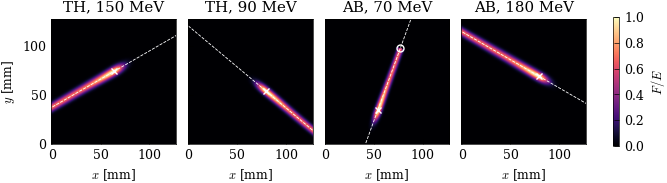

In [9]:
energy_rel = energy / batch["condition"][:, 2].view(-1, 1, 1, 1, 1)     # F / E

fig, axes = plt.subplots(1, 4, figsize=(17.2 * CM, 4.8 * CM), sharey=True, layout="constrained")
for b, ax in enumerate(axes):
    im = show_slice(ax, energy_rel, b, cmap="magma", vmin=0, vmax=1)
axes[0].set_ylabel("$y$ [mm]")
fig.colorbar(im, ax=axes, shrink=0.8, label="$F/E$")
finish(fig, "fig4_energy_slices")

### The 3D field is one function on the $(\delta, r)$ plane

The energy prior evaluates the same function for every voxel, and that function depends only on $\delta$ and $r$. Plotting the voxels of the 3D field against $\delta$ shows that those close to the axis ($r < 0.5$ mm) sit on the on-axis profile, while voxels further out (grey) are lower because of the lateral Gaussian. The beam is the AB 70 MeV one: its $s'$ lies inside the patch, so the jump at $s'$ is visible too.

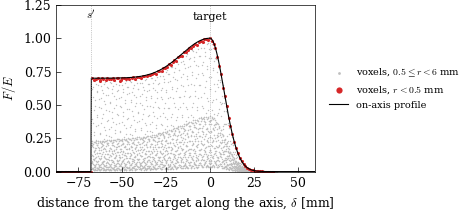

In [10]:
b = 2
t, u, L, E = beam_geometry(batch, b)
X, Y, Z = PATCH
ijk = np.stack(np.meshgrid(np.arange(X), np.arange(Y), np.arange(Z), indexing="ij"), axis=-1).reshape(-1, 3)
p = patch_to_lps(ijk)                                       # voxel centres, LPS [mm]
delta_vox = (p - t) @ u
r_vox = np.linalg.norm(p - t - delta_vox[:, None] * u, axis=1)
F_vox = energy_rel[b, 0].numpy().reshape(-1)

delta = np.arange(-L - 20.0, 60.0, 0.25)
profile = probe(batch, b, t + delta[0] * u, 0.25 * u, len(delta), kind="energy") / E

near, mid = r_vox < 0.5, (r_vox >= 0.5) & (r_vox < 6.0)
fig, ax = plt.subplots(figsize=(12.0 * CM, 5.6 * CM), layout="constrained")
ax.scatter(delta_vox[mid], F_vox[mid], s=1, c="0.75", lw=0, label=r"voxels, $0.5 \leq r < 6$ mm")
ax.scatter(delta_vox[near], F_vox[near], s=5, c="C3", lw=0, label=r"voxels, $r < 0.5$ mm")
ax.plot(delta, profile, "k", lw=0.8, label="on-axis profile")
for pos, text in ((0.0, "target"), (-L, "$s'$")):
    ax.axvline(pos, color="0.6", lw=0.5, ls=":")
    ax.text(pos, 1.12, text, ha="center", va="bottom", fontsize=8)
ax.set_xlim(delta[0], delta[-1])
ax.set_ylim(0, 1.25)
ax.set_xlabel(r"distance from the target along the axis, $\delta$ [mm]")
ax.set_ylabel("$F/E$")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=7, markerscale=2)
finish(fig, "fig5_energy_voxels")

## 6. Energy dependence

The fitted length $L(E) = a_g E^{b_g} + c_g$ differs between the groups (TH: thorax, AB: abdomen). At higher energy $L$ is longer, so $s'$ moves further away from the target, while the target (the Bragg position) stays where it is. At the same energy the TH fit gives a longer path, because of the low density of the lungs.

The right panel shows the on-axis profile of the first beam for five energies, using the energy and group override of `probe`.

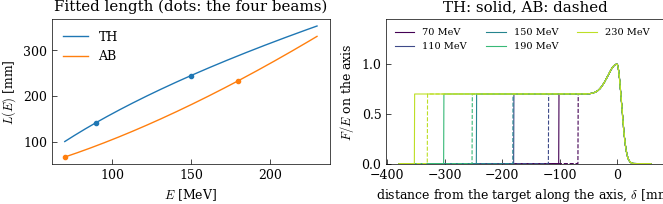

In [11]:
energies = np.linspace(70, 230, 161)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17.2 * CM, 5.4 * CM), layout="constrained")
for group, color in (("TH", "C0"), ("AB", "C1")):
    ax1.plot(energies, [fitted_length(group, e) for e in energies], color=color, label=group)
for b in range(len(BEAMS)):
    _, _, L, E = beam_geometry(batch, b)
    ax1.plot(E, L, "o", ms=3, color="C0" if batch["group"][b] == "TH" else "C1")
ax1.set_xlabel("$E$ [MeV]")
ax1.set_ylabel("$L(E)$ [mm]")
ax1.set_title("Fitted length (dots: the four beams)")
ax1.legend()

t, u, _, _ = beam_geometry(batch, 0)
delta = np.arange(-380.0, 60.0, 0.5)
for e, color in zip((70, 110, 150, 190, 230), plt.cm.viridis(np.linspace(0.0, 0.9, 5))):
    for group, ls in (("TH", "-"), ("AB", "--")):
        prof = probe(batch, 0, t + delta[0] * u, 0.5 * u, len(delta), kind="energy", energy=e, group=group) / e
        ax2.plot(delta, prof, ls=ls, color=color, lw=0.8, label=f"{e} MeV" if group == "TH" else None)
ax2.set_ylim(0, 1.45)
ax2.set_xlabel(r"distance from the target along the axis, $\delta$ [mm]")
ax2.set_ylabel("$F/E$ on the axis")
ax2.set_title("TH: solid, AB: dashed")
ax2.legend(loc="upper left", ncol=3, fontsize=7)
finish(fig, "fig6_energy_dependence")

## 7. Network input

`predict` concatenates the two priors to the CT: `torch.cat([ct, geometric, energy], dim=1)`, of shape `(B, 3, 128, 128, 32)`. The figure shows the three channels of one beam in the same slice, now on their true scale (the maximum of the energy prior is $E$).

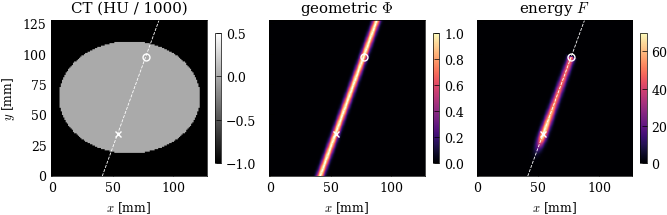

In [12]:
b = 2
fig, axes = plt.subplots(1, 3, figsize=(17.2 * CM, 5.4 * CM), sharey=True, layout="constrained")
channels = (("CT (HU / 1000)", "gray", -1.0, 0.5), (r"geometric $\Phi$", "magma", None, None),
            (r"energy $F$", "magma", None, None))
for c, (ax, (title, cmap, vmin, vmax)) in enumerate(zip(axes, channels)):
    im = show_slice(ax, x[:, c:c + 1], b, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.8)
axes[0].set_ylabel("$y$ [mm]")
finish(fig, "fig7_network_input")

In [13]:
def beam(b, fits):
    """Target t (LPS), unit direction u, fitted length L and energy E of beam b."""
    s = batch["phys_source"][b].double().numpy()
    t = batch["phys_target"][b].double().numpy()
    u = (t - s) / np.linalg.norm(t - s)
    E = float(batch["condition"][b, 2])
    a, p, c = fits[batch["group"][b]]
    return t, u, max(a * E**p + c, 1.0), E


def target_voxel(b):
    ijk = np.round(lps_to_patch(batch["phys_target"][b].double().numpy())).astype(int)
    return tuple(np.clip(ijk, 0, np.array(PATCH) - 1))


def across_profile(**kwargs):
    return probe(batch, b, t + r[0] * e_perp, 0.05 * e_perp, len(r), **kwargs)


def along_profile(**kwargs):
    return probe(batch, b, t + delta[0] * u, 0.25 * u, len(delta), **kwargs)


def slice_plot(ax, volume, title):
    """Axial slice of volume (B, 1, X, Y, Z) through the target of beam b, beam axis, target and s'."""
    t_vox = lps_to_patch(t)
    X, Y, _ = PATCH
    im = ax.imshow(volume[b, 0, :, :, int(round(t_vox[2]))].T, origin="lower", cmap="magma", vmin=0, vmax=1,
                   extent=[-0.5, X - 0.5, -0.5, Y - 0.5])
    t_mm = t_vox[:2] * SPACING[:2]
    ax.plot(*np.c_[t_mm - 400 * u[:2], t_mm + 400 * u[:2]], ls="--", lw=0.6, color="w")
    ax.plot(*t_mm, "x", color="w", ms=5, mew=1)
    s_mm = lps_to_patch(t - L_now * u)[:2] * SPACING[:2]
    if (s_mm >= 0).all() and (s_mm < [X, Y]).all():
        ax.plot(*s_mm, "o", mfc="none", mec="w", ms=5, mew=1)
    ax.set_xlim(-0.5, X - 0.5)
    ax.set_ylim(-0.5, Y - 0.5)
    ax.set_title(title)
    ax.set_xlabel("$x$ [mm]")
    ax.set_ylabel("$y$ [mm]")
    return im

In [14]:
BEAMS = [("TH", 150.0,  30.0, (  0.0,  10.0, 0.0)),
         ("TH",  90.0, 140.0, ( 15.0, -10.0, 0.0)),
         ("AB",  70.0, 250.0, (-10.0, -30.0, 0.0)),
         ("AB", 180.0, 330.0, ( 15.0,   5.0, 0.0))]


Geometric prior (4, 1, 128, 128, 32), sigma = 2.0 mm
beam group     max at target voxels > 0.5
   0    TH   1.000     1.000          696
   1    TH   1.000     1.000          786
   2    AB   1.000     1.000          640
   3    AB   1.000     1.000          696

Energy prior (4, 1, 128, 128, 32)
beam group E [MeV]  L [mm] s in patch     max at target voxels > 0.5 max
   0    TH     150   244.9      False   150.0     150.0              574
   1    TH      90   142.8      False    90.0      90.0              344
   2    AB      70    67.6       True    70.0      70.0              309
   3    AB     180   233.6      False   180.0     180.0              622


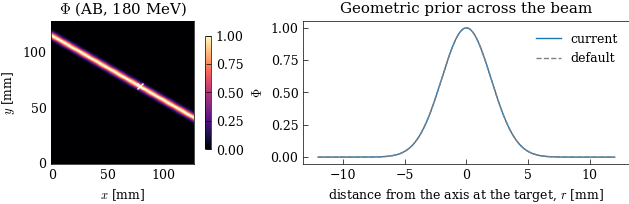

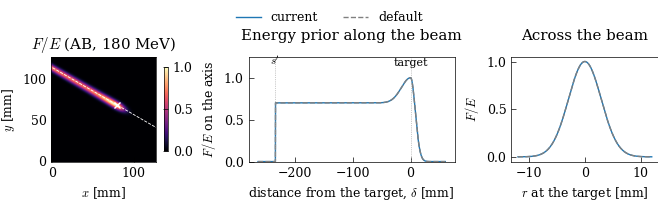

In [15]:
# ---------------- parameters: edit, then re-run this cell ----------------
B_IDX = 3                    # beam of the batch to plot
SAVE_PRIORS = False          # True: also save the two priors as .npy files

GEOMETRIC = dict(
    sigma=2.0,               # tube width [mm]
)
ENERGY = dict(
    range_fits={"TH": (36.99015255, 0.5, -208.1400),    # L(E) = a * E**b + c [mm]
                "AB": (0.09815625, 1.485708, 13.5085)},
    sigma_lat0=2.0,          # lateral sigma at the fitted source [mm]
    sigma_lat_slope=0.004,   # lateral sigma growth per mm of depth
    plateau=0.7,             # entrance plateau, relative to the peak
    sigma_entrance=16.0,     # width of the peak before the target [mm]
    sigma_distal=8.0,        # fall-off behind the target [mm]
)
# -------------------------------------------------------------------------

# 1. The two priors, (B, 1, X, Y, Z) each
geo_prior = trainer.generate_prior(batch=batch, kind="geometric", **GEOMETRIC)
energy_prior = trainer.generate_prior(batch=batch, kind="energy", **ENERGY)
if SAVE_PRIORS:
    np.save("geometric_prior.npy", geo_prior.numpy())
    np.save("energy_prior.npy", energy_prior.numpy())


# 2. Summary per beam
print(f"Geometric prior {tuple(geo_prior.shape)}, sigma = {GEOMETRIC['sigma']} mm")
print(f"{'beam':>4} {'group':>5} {'max':>7} {'at target':>9} {'voxels > 0.5':>12}")
for b in range(len(batch["group"])):
    vol = geo_prior[b, 0]
    print(f"{b:>4} {batch['group'][b]:>5} {vol.max().item():7.3f} {vol[target_voxel(b)].item():9.3f}"
          f" {int((vol > 0.5).sum()):12d}")

print(f"\nEnergy prior {tuple(energy_prior.shape)}")
print(f"{'beam':>4} {'group':>5} {'E [MeV]':>7} {'L [mm]':>7} {'s in patch':>10} {'max':>7} {'at target':>9}"
      f" {'voxels > 0.5 max':>16}")
for b in range(len(batch["group"])):
    vol = energy_prior[b, 0]
    t, u, L, E = beam(b, ENERGY["range_fits"])
    s_fit = lps_to_patch(t - L * u)
    inside = bool((s_fit >= 0).all() and (s_fit <= np.array(PATCH) - 1).all())
    print(f"{b:>4} {batch['group'][b]:>5} {E:7.0f} {L:7.1f} {str(inside):>10} {vol.max().item():7.1f}"
          f" {vol[target_voxel(b)].item():9.1f} {int((vol > 0.5 * vol.max()).sum()):16d}")


# 3. Plot helpers for beam B_IDX (dashed curves: default parameters)
b = B_IDX
t, u, L_now, E = beam(b, ENERGY["range_fits"])
L_def = beam(b, FITS)[2]                                    # FITS: the default fits from section 3
e_perp = np.array([-u[1], u[0], 0.0])
e_perp /= np.linalg.norm(e_perp)                            # unit vector across the beam
r = np.arange(-12.0, 12.0 + 1e-9, 0.05)                     # across the beam, at the target [mm]
delta = np.arange(-max(L_now, L_def) - 30.0, 60.0, 0.25)    # along the beam, from the target [mm]


# 4. Geometric prior: slice and profile across the beam
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17.2 * CM, 5.4 * CM), layout="constrained",
                               gridspec_kw={"width_ratios": [1, 1.4]})
im = slice_plot(ax1, geo_prior, rf"$\Phi$ ({batch['group'][b]}, {E:.0f} MeV)")
fig.colorbar(im, ax=ax1, shrink=0.8)
ax2.plot(r, across_profile(**GEOMETRIC), label="current")
ax2.plot(r, across_profile(), "--", color="0.5", label="default")
ax2.set_xlabel(r"distance from the axis at the target, $r$ [mm]")
ax2.set_ylabel(r"$\Phi$")
ax2.set_title("Geometric prior across the beam")
ax2.legend(loc="upper right")
finish(fig, "playground_geometric")

# 5. Energy prior: slice, profile along the beam, profile across it at the target
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17.2 * CM, 5.4 * CM), layout="constrained",
                                    gridspec_kw={"width_ratios": [1, 1.4, 1]})
im = slice_plot(ax1, energy_prior / batch["condition"][:, 2].view(-1, 1, 1, 1, 1),
                rf"$F/E$ ({batch['group'][b]}, {E:.0f} MeV)")
fig.colorbar(im, ax=ax1, shrink=0.8)
ax2.plot(delta, along_profile(kind="energy", **ENERGY) / E)
ax2.plot(delta, along_profile(kind="energy") / E, "--", color="0.5")
for pos, text in ((0.0, "target"), (-L_now, "$s'$")):
    ax2.axvline(pos, color="0.6", lw=0.5, ls=":")
    ax2.text(pos, 1.12, text, ha="center", va="bottom", fontsize=8)
ax2.set_ylim(0, 1.25)
ax2.set_xlabel(r"distance from the target, $\delta$ [mm]")
ax2.set_ylabel("$F/E$ on the axis")
ax2.set_title("Energy prior along the beam", pad=12)
ax3.plot(r, across_profile(kind="energy", **ENERGY) / E, label="current")
ax3.plot(r, across_profile(kind="energy") / E, "--", color="0.5", label="default")
ax3.set_xlabel("$r$ at the target [mm]")
ax3.set_ylabel("$F/E$")
ax3.set_title("Across the beam", pad=12)
fig.legend(*ax3.get_legend_handles_labels(), loc="outside upper center", ncol=2)
finish(fig, "playground_energy")

## 8. Check: the priors do not depend on the CT values

The same batch with a random CT: both priors stay bit-identical, because they only use the geometry, the energy and the group.

In [16]:
noisy = dict(batch, ct=torch.randn_like(batch["ct"]))
for kind in ("geometric", "energy"):
    same = torch.equal(trainer.generate_prior(batch=noisy, kind=kind), trainer.generate_prior(batch=batch, kind=kind))
    print(f"{kind:9s}: identical with a random CT -> {same}")

geometric: identical with a random CT -> True
energy   : identical with a random CT -> True


## 9. How to use

In [1]:
import os
os.environ['OPENBLAS_NUM_THREADS'] = '1'


In [4]:
import torch
from scripts.training_boys import DoseTrainer
import matplotlib.pyplot as plt

# A batch with one beam, in the format the priors expect (B = 1)
batch = {
    "ct": torch.zeros(1, 1, 128, 128, 32),                      # CT patch (B, 1, X, Y, Z); only shape, device, dtype are used
    "phys_source": torch.tensor([[-259.8, -149.5, -452.0]]),    # ray source (B, 3), LPS [mm], from the ray JSON
    "phys_target": torch.tensor([[0.0, 0.5, -452.0]]),          # ray target (B, 3), LPS [mm]
    "condition": torch.tensor([[0.0, 0.0, 150.0]]),             # (B, >=3), beam energy [MeV] in column 2
    "affine_trans": torch.tensor([[[-1.0, 0.0, 0.0, 221.0],     # (B, 4, 4) voxel -> world RAS affine of the
                                   [0.0, -1.0, 0.0, 219.5],     # ORIGINAL (uncropped) CT, as MONAI loads it:
                                   [0.0, 0.0, 3.0, -650.0],     # 1 x 1 x 3 mm voxels, origin (-221, -219.5, -650) LPS
                                   [0.0, 0.0, 0.0, 1.0]]]),
    "orig_shape": torch.tensor([[443, 440, 133]]),              # (B, 3) shape of the original CT
    "z_start": torch.tensor([50]),                              # (B,) first slice of the patch in the original CT
    "group": ["AB"],                                            # anatomical group per beam: "TH" or "AB"
}

trainer = DoseTrainer(model=torch.nn.Identity())                # the model plays no role in prior generation
geo = trainer.generate_prior(batch=batch, kind="geometric")                       # (1, 1, 128, 128, 32): 1 on the beam axis
energy = trainer.generate_prior(batch=batch, kind="energy")     # (1, 1, 128, 128, 32): E at the ray target
x = torch.cat([batch["ct"], geo, energy], dim=1)                # model input (1, 3, 128, 128, 32)

print("model input:", tuple(x.shape))
print("at the target voxel (64, 64, 16): geometric", round(geo[0, 0, 64, 64, 16].item(), 4),
      "| energy", round(energy[0, 0, 64, 64, 16].item(), 2))

model input: (1, 3, 128, 128, 32)
at the target voxel (64, 64, 16): geometric 1.0 | energy 150.0


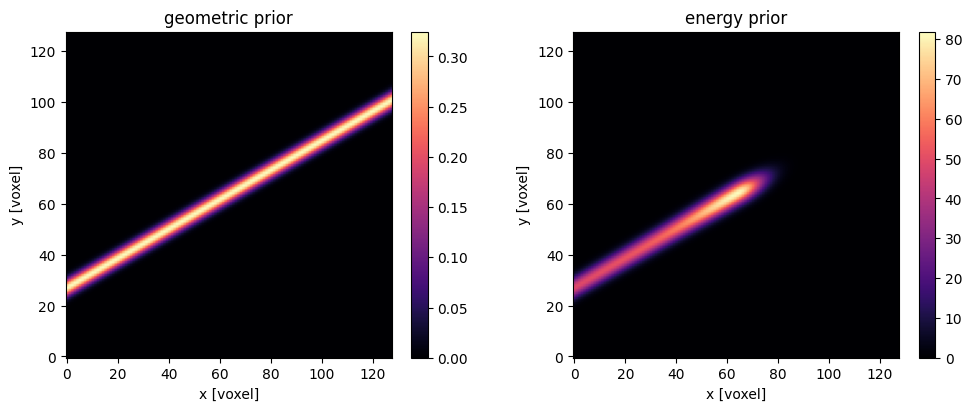

In [5]:
k = 15                                                     # axial slice through the target
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, field, title in zip(axes, (geo, energy), ("geometric prior", "energy prior")):
    im = ax.imshow(field[0, 0, :, :, k].cpu().numpy().T, origin="lower", cmap="magma")
    ax.set_title(title)
    ax.set_xlabel("x [voxel]")
    ax.set_ylabel("y [voxel]")
    fig.colorbar(im, ax=ax)
plt.show()

In [ ]:
import torch
from scripts.training_boys import DoseTrainer
import matplotlib.pyplot as plt

# A batch with one beam, in the format the priors expect (B = 1)
batch = {
    "ct": torch.zeros(1, 1, 128, 128, 32),                      # CT patch (B, 1, X, Y, Z); only shape, device, dtype are used
    "phys_source": torch.tensor([[-259.8, -149.5, -452.0]]),    # ray source (B, 3), LPS [mm], from the ray JSON
    "phys_target": torch.tensor([[0.0, 0.5, -452.0]]),          # ray target (B, 3), LPS [mm]
    "condition": torch.tensor([[0.0, 0.0, 150.0]]),             # (B, >=3), beam energy [MeV] in column 2
    "affine_trans": torch.tensor([[[-1.0, 0.0, 0.0, 221.0],     # (B, 4, 4) voxel -> world RAS affine of the
                                   [0.0, -1.0, 0.0, 219.5],     # ORIGINAL (uncropped) CT, as MONAI loads it:
                                   [0.0, 0.0, 3.0, -650.0],     # 1 x 1 x 3 mm voxels, origin (-221, -219.5, -650) LPS
                                   [0.0, 0.0, 0.0, 1.0]]]),
    "orig_shape": torch.tensor([[443, 440, 133]]),              # (B, 3) shape of the original CT
    "z_start": torch.tensor([50]),                              # (B,) first slice of the patch in the original CT
    "group": ["AB"],                                            # anatomical group per beam: "TH" or "AB"
}

trainer = DoseTrainer(model=torch.nn.Identity())                # the model plays no role in prior generation
geo = trainer.generate_prior(batch=batch, kind="geometric")                       # (1, 1, 128, 128, 32): 1 on the beam axis
energy = trainer.generate_prior(batch=batch, kind="energy")     # (1, 1, 128, 128, 32): E at the ray target
x = torch.cat([batch["ct"], geo, energy], dim=1)                # model input (1, 3, 128, 128, 32)

print("model input:", tuple(x.shape))
print("at the target voxel (64, 64, 16): geometric", round(geo[0, 0, 64, 64, 16].item(), 4),
      "| energy", round(energy[0, 0, 64, 64, 16].item(), 2))